In [4]:
# CELL 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:
# CELL 2: Load Dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print("\nFirst Five Rows:")
display(X.head())

print("\nMissing Values:", X.isnull().sum().sum())

print("\nTarget Classes:")
print(pd.Series(y).value_counts())

Dataset Shape: (569, 30)

First Five Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Missing Values: 0

Target Classes:
target
1    357
0    212
Name: count, dtype: int64


In [6]:
# CELL 3: Split and Scale Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)
print("Preprocessing completed successfully!")

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)
Preprocessing completed successfully!


In [7]:
# CELL 4: Train SVM and Random Forest

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(kernel="rbf", probability=True, random_state=42)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

print("\nSVM Classification Report")
print(classification_report(y_test, svm_pred))

print("\nRandom Forest Classification Report")
print(classification_report(y_test, rf_pred))

SVM Accuracy: 0.9824561403508771
Random Forest Accuracy: 0.956140350877193

SVM Classification Report
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Decision Tree Accuracy: 0.9210526315789473

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        42
           1       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



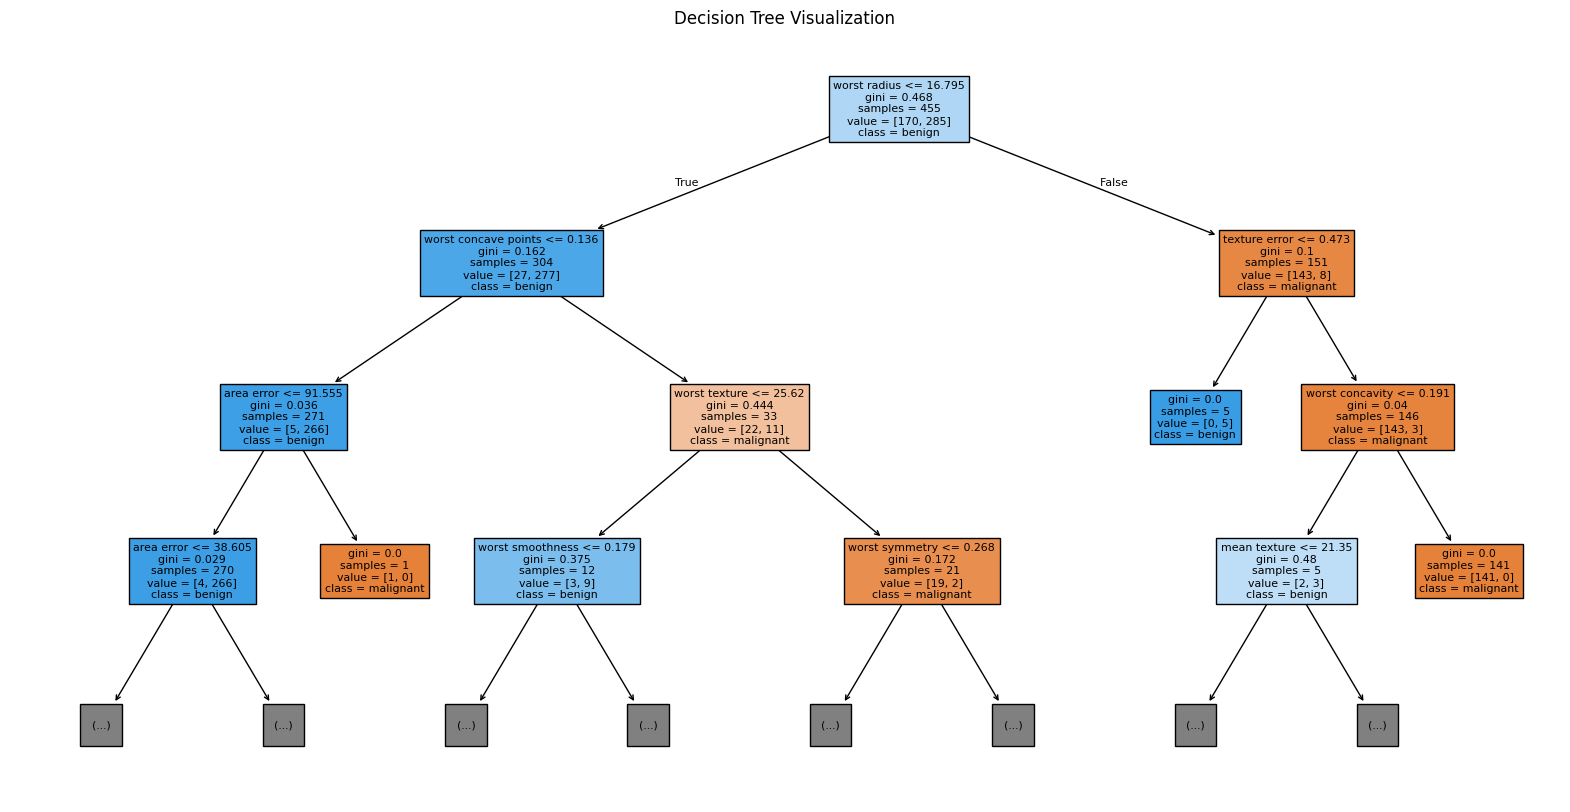

In [8]:
# CELL 5: Decision Tree

from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree Visualization")
plt.show()

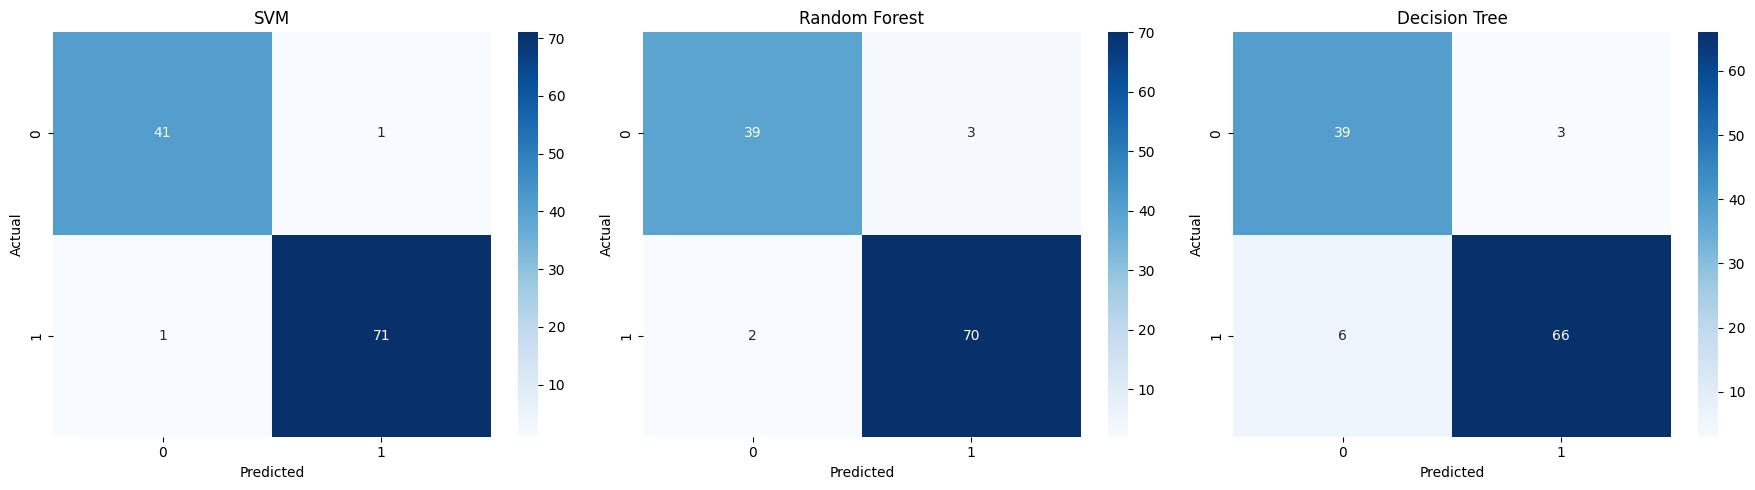

In [9]:
# CELL 6: Confusion Matrices

from sklearn.metrics import confusion_matrix

models = {
    "SVM": (y_test, svm_pred),
    "Random Forest": (y_test, rf_pred),
    "Decision Tree": (y_test, dt_pred)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (actual, predicted)) in zip(axes, models.items()):
    cm = confusion_matrix(actual, predicted)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Model,Accuracy
0,SVM,0.982456
1,Random Forest,0.956140
2,Decision Tree,0.921053


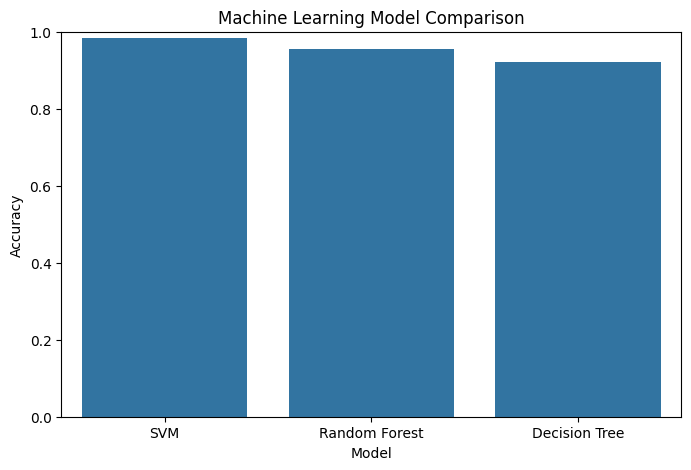

In [10]:
# CELL 7: Accuracy Comparison

results = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, dt_pred)
    ]
})

display(results)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Machine Learning Model Comparison")
plt.show()

In [11]:
# CELL 8: Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold

parameter_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.01, 0.001],
    "kernel": ["rbf", "linear"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    SVC(),
    parameter_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      grid_search.best_score_)

best_svm = grid_search.best_estimator_

tuned_pred = best_svm.predict(X_test_scaled)

print("Tuned SVM Test Accuracy:",
      accuracy_score(y_test, tuned_pred))

Best Parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best Cross-Validation Accuracy: 0.9758241758241759
Tuned SVM Test Accuracy: 0.9824561403508771


Scores: [0.96703297 1.         0.95604396 0.98901099 0.98901099]
Mean Accuracy: 0.9802197802197803
Standard Deviation: 0.016150481820548422


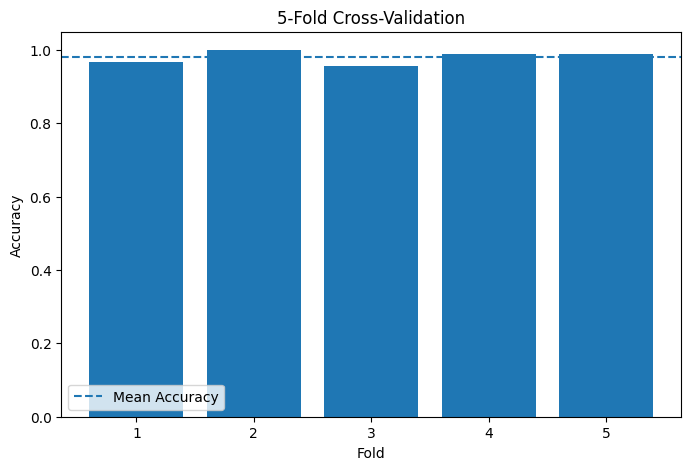

In [12]:
# CELL 9: Cross-Validation Scores

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_svm,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 6),
    cv_scores
)

plt.axhline(
    cv_scores.mean(),
    linestyle="--",
    label="Mean Accuracy"
)

plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation")
plt.legend()
plt.show()

In [13]:
# CELL 10: K-Means Clustering

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

clusters = kmeans.fit_predict(X_train_scaled)

print("Silhouette Score:",
      silhouette_score(X_train_scaled, clusters))

Silhouette Score: 0.35479337852343096


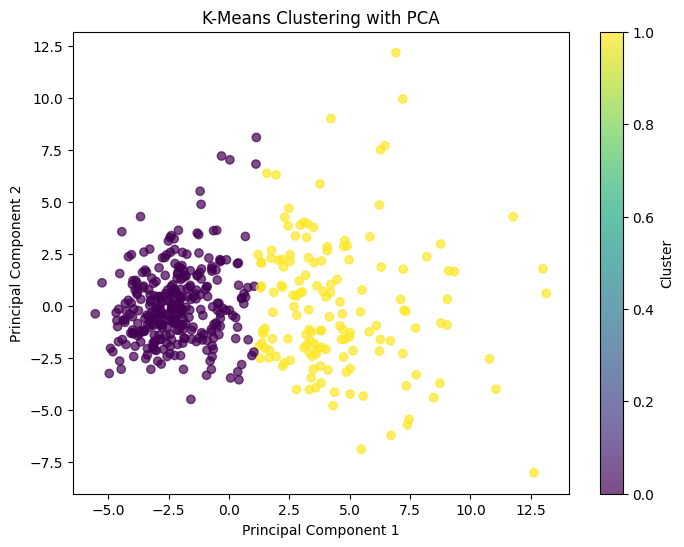

Explained Variance: [0.44413492 0.18944618]
Total Variance Retained: 0.6335811006772492


In [14]:
# CELL 11: PCA Visualization

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering with PCA")
plt.colorbar(label="Cluster")
plt.show()

print("Explained Variance:",
      pca.explained_variance_ratio_)

print("Total Variance Retained:",
      pca.explained_variance_ratio_.sum())

In [15]:
# CELL 12: Load Fashion-MNIST

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

(x_train, y_train), (x_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (60000, 28, 28)
Testing Shape: (10000, 28, 28)


In [16]:
# CELL 13: FNN Model

fnn = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

fnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fnn.summary()

fnn_history = fnn.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

fnn_loss, fnn_accuracy = fnn.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("FNN Test Accuracy:", fnn_accuracy)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7872 - loss: 0.6055 - val_accuracy: 0.8478 - val_loss: 0.4193
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8469 - loss: 0.4232 - val_accuracy: 0.8595 - val_loss: 0.3841
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8634 - loss: 0.3779 - val_accuracy: 0.8702 - val_loss: 0.3668
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8694 - loss: 0.3572 - val_accuracy: 0.8697 - val_loss: 0.3544
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8751 - loss: 0.3409 - val_accuracy: 0.8757 - val_loss: 0.3343
FNN Test Accuracy: 0.8654000163078308


In [17]:
# CELL 14: CNN Model

cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_history = cnn.fit(
    x_train[..., None],
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

cnn_loss, cnn_accuracy = cnn.evaluate(
    x_test[..., None],
    y_test,
    verbose=0
)

print("CNN Test Accuracy:", cnn_accuracy)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 59ms/step - accuracy: 0.7880 - loss: 0.5935 - val_accuracy: 0.8618 - val_loss: 0.3737
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 57ms/step - accuracy: 0.8653 - loss: 0.3729 - val_accuracy: 0.8748 - val_loss: 0.3367
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 25s 60ms/step - accuracy: 0.8822 - loss: 0.3243 - val_accuracy: 0.8920 - val_loss: 0.2957
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 57ms/step - accuracy: 0.8932 - loss: 0.2930 - val_accuracy: 0.9010 - val_loss: 0.2697
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 57ms/step - accuracy: 0.9005 - loss: 0.2721 - val_accuracy: 0.9035 - val_loss: 0.2669
CNN Test Accuracy: 0.8984000086784363


,Model,Test Accuracy
0,FNN,0.8654
1,CNN,0.8984


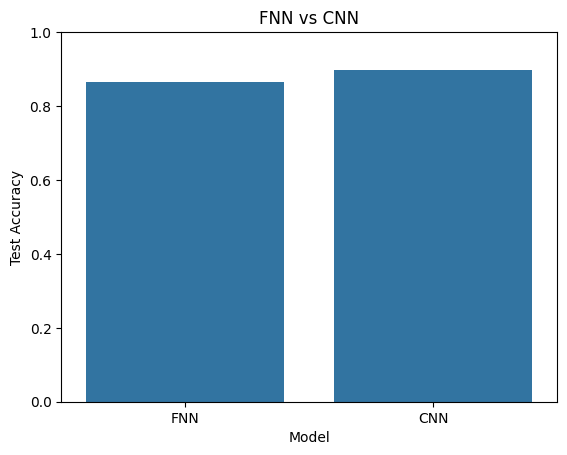

In [18]:
# CELL 15: FNN vs CNN Comparison

comparison = pd.DataFrame({
    "Model": ["FNN", "CNN"],
    "Test Accuracy": [fnn_accuracy, cnn_accuracy]
})

display(comparison)

sns.barplot(
    data=comparison,
    x="Model",
    y="Test Accuracy"
)

plt.ylim(0, 1)
plt.title("FNN vs CNN")
plt.show()

In [19]:
# CELL 16: Load MNIST for GAN

(x_gan, _), (_, _) = keras.datasets.mnist.load_data()

x_gan = x_gan.astype("float32")
x_gan = (x_gan - 127.5) / 127.5

x_gan = x_gan[..., None]

BATCH_SIZE = 128
LATENT_DIM = 100

gan_dataset = (
    tf.data.Dataset.from_tensor_slices(x_gan)
    .shuffle(10000)
    .batch(BATCH_SIZE)
)

In [20]:
# CELL 17: Build Generator and Discriminator

generator = keras.Sequential([
    layers.Input(shape=(LATENT_DIM,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(
        64, 4,
        strides=2,
        padding="same",
        use_bias=False
    ),

    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        1, 4,
        strides=2,
        padding="same",
        activation="tanh"
    )
])

discriminator = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64, 4,
        strides=2,
        padding="same"
    ),

    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, 4,
        strides=2,
        padding="same"
    ),

    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

generator.summary()
discriminator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# CELL 18: Train GAN

cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=True
)

g_optimizer = keras.optimizers.Adam(1e-4)
d_optimizer = keras.optimizers.Adam(1e-4)

@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        [batch_size, LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        gen_loss = cross_entropy(
            tf.ones_like(fake_output),
            fake_output
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output),
            fake_output
        )

        disc_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


EPOCHS = 10

for epoch in range(EPOCHS):

    for batch in gan_dataset:
        g_loss, d_loss = train_step(batch)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {float(g_loss):.4f} | "
        f"Discriminator Loss: {float(d_loss):.4f}"
    )

Epoch 1/10 | Generator Loss: 0.8952 | Discriminator Loss: 1.2859
Epoch 2/10 | Generator Loss: 0.7433 | Discriminator Loss: 1.3931
Epoch 3/10 | Generator Loss: 0.9135 | Discriminator Loss: 1.2811
Epoch 4/10 | Generator Loss: 0.7968 | Discriminator Loss: 1.2409
Epoch 5/10 | Generator Loss: 0.8633 | Discriminator Loss: 1.2325
Epoch 6/10 | Generator Loss: 1.0907 | Discriminator Loss: 1.0332
Epoch 7/10 | Generator Loss: 1.0886 | Discriminator Loss: 1.1623
Epoch 8/10 | Generator Loss: 1.0412 | Discriminator Loss: 1.2322
Epoch 9/10 | Generator Loss: 0.9650 | Discriminator Loss: 1.2346
Epoch 10/10 | Generator Loss: 0.9277 | Discriminator Loss: 1.4415


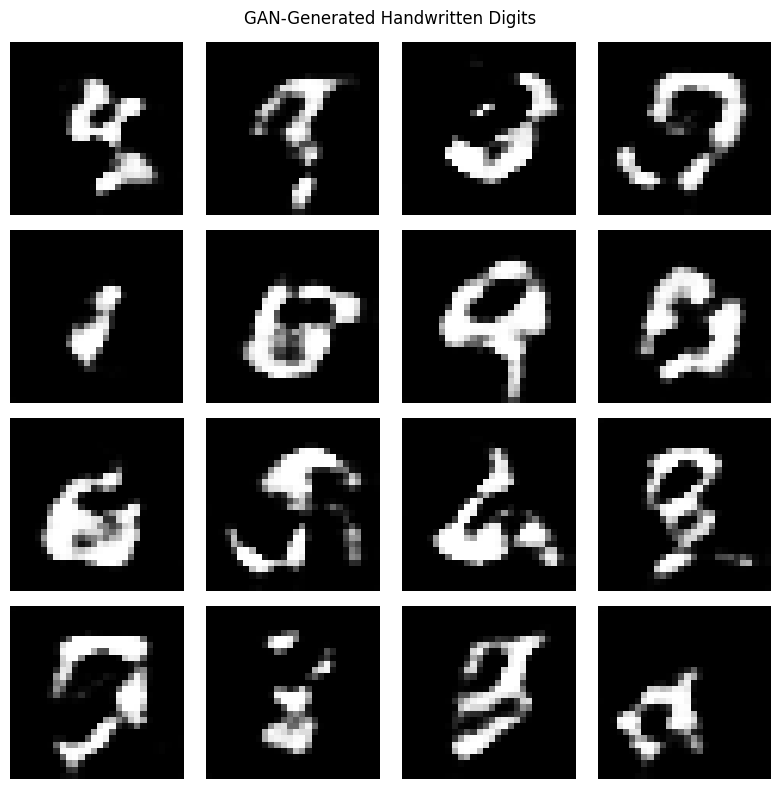

In [31]:
# CELL 19: Generate Synthetic Images

noise = tf.random.normal([16, LATENT_DIM])

generated_images = generator(
    noise,
    training=False
)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("GAN-Generated Handwritten Digits")
plt.tight_layout()
plt.show()

In [32]:
# CELL 20: Save Models

fnn.save("/content/fnn_model.keras")
cnn.save("/content/cnn_model.keras")
generator.save("/content/gan_generator.keras")

import joblib

joblib.dump(
    best_svm,
    "/content/best_svm_model.joblib"
)

joblib.dump(
    scaler,
    "/content/standard_scaler.joblib"
)

print("All models saved successfully!")

All models saved successfully!


In [33]:
from google.colab import files

files.download("/content/best_svm_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import joblib

model = joblib.load('/content/best_svm_model.joblib')

print("Model loaded successfully!")
print(model)

Model loaded successfully!
SVC(C=0.1, kernel='linear')


In [26]:
from sklearn.datasets import load_breast_cancer

# Load the dataset
data = load_breast_cancer()

# Select one sample
sample = data.data[0].reshape(1, -1)

# Predict using your saved model
prediction = model.predict(sample)

# Display the result
if prediction[0] == 0:
    print("Prediction: Malignant")
else:
    print("Prediction: Benign")

Prediction: Malignant


In [29]:
import joblib
from sklearn.datasets import load_breast_cancer

# Load saved model and scaler
model = joblib.load('/content/best_svm_model.joblib')
scaler = joblib.load('/content/standard_scaler.joblib')

# Load dataset
data = load_breast_cancer()

# Select a sample
sample = data.data[0].reshape(1, -1)

# Standardize the sample
sample_scaled = scaler.transform(sample)

# Predict
prediction = model.predict(sample_scaled)

# Display result
print("Predicted class:", data.target_names[prediction[0]])

Predicted class: malignant


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [28]:
print(type(model))
print(model.get_params())

<class 'sklearn.svm._classes.SVC'>
{'C': 0.1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}
